In [3]:
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import shutil
import os

source = '/content/drive/MyDrive/dl_seg/luna16-dp2d.zip'

destination = '/content/dataset.zip'

shutil.copy(source, destination)
print("Done", round(os.path.getsize(destination) / (1024*1024), 2), "MB")

Done 1725.94 MB


In [8]:
!unzip -q /content/dataset.zip -d /content/dataset

In [66]:
import pandas as pd

meta_path = '/content/dataset/metadata.csv'
df = pd.read_csv(meta_path)

print(df.shape)
print(df.columns.tolist())
display(df.head())

(6216, 13)
['filename', 'subset', 'original_scan', 'percentile', 'slice_index', 'shape', 'dtype', 'min', 'max', 'mean', 'std', 'lung_mask_path', 'nodule_mask_path']


,filename,subset,original_scan,percentile,slice_index,shape,dtype,min,max,mean,std,lung_mask_path,nodule_mask_path
0,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,10,29,512x512,int16,-1000.0,1412.0,-266.081429,435.304161,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
1,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,25,74,512x512,int16,-1000.0,1449.0,-384.904358,464.533404,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
2,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,40,118,512x512,int16,-1000.0,1385.0,-444.566818,479.061742,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
3,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,50,147,512x512,int16,-1000.0,1446.0,-464.476223,482.300091,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
4,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,60,176,512x512,int16,-1000.0,1560.0,-480.510075,481.659126,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...


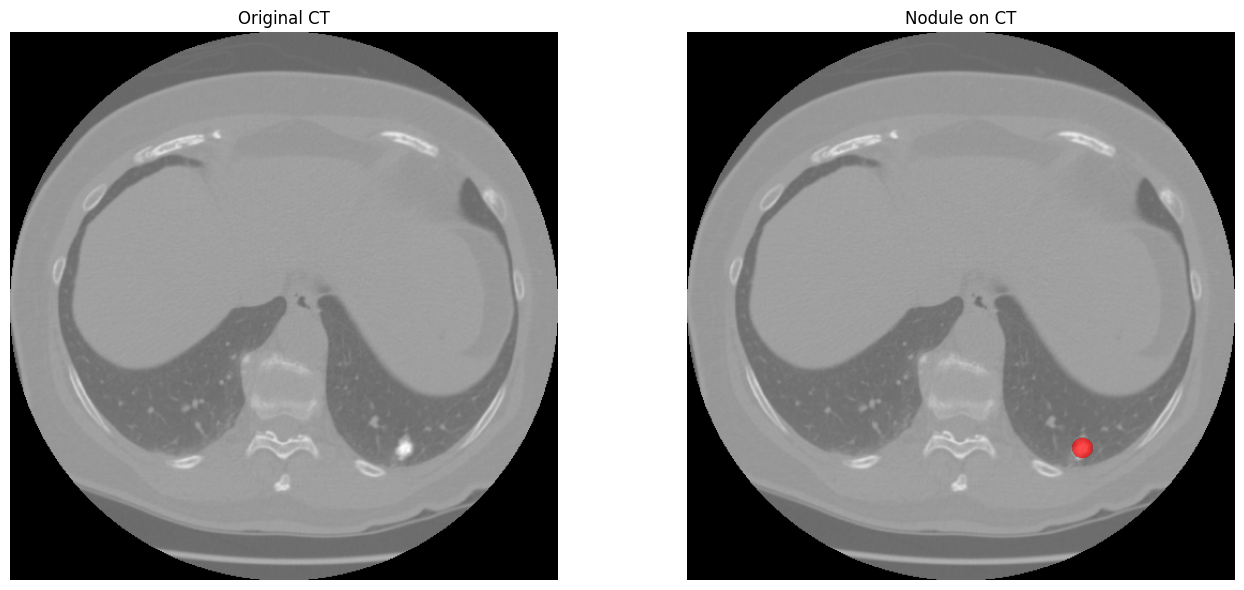

In [ ]:
import numpy as np

slices_dir = '/content/dataset/slices'
lung_masks_dir = '/content/dataset/masks/lung_mask'
nodule_masks_dir = '/content/dataset/masks/nodule_mask'

slice_files = sorted(os.listdir(slices_dir))
first_sample = slice_files[3473]

sample_base = first_sample.replace('.npy', '')
nodule_mask_name = f"{sample_base}_nodule_mask.npy"

slice_img = np.load(os.path.join(slices_dir, first_sample))
nodule_mask = np.load(os.path.join(nodule_masks_dir, nodule_mask_name))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(slice_img, cmap='gray')
axes[0].set_title("Original CT")
axes[0].axis('off')

axes[1].imshow(slice_img, cmap='gray')
axes[1].imshow(np.ma.masked_where(nodule_mask == 0, nodule_mask), cmap='autumn', alpha=0.7)
axes[1].set_title("Nodule on CT")
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
meta_path = '/content/dataset/metadata.csv'
df = pd.read_csv(meta_path)

print(df.info())

display(df.describe())
display(df.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6216 entries, 0 to 6215
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   filename          6216 non-null   object 
 1   subset            6216 non-null   object 
 2   original_scan     6216 non-null   object 
 3   percentile        6216 non-null   int64  
 4   slice_index       6216 non-null   int64  
 5   shape             6216 non-null   object 
 6   dtype             6216 non-null   object 
 7   min               6216 non-null   float64
 8   max               6216 non-null   float64
 9   mean              6216 non-null   float64
 10  std               6216 non-null   float64
 11  lung_mask_path    6216 non-null   object 
 12  nodule_mask_path  6216 non-null   object 
dtypes: float64(4), int64(2), object(7)
memory usage: 631.4+ KB
None


,percentile,slice_index,min,max,mean,std
count,6216.000000,6216.000000,6216.000000,6216.000000,6216.000000,6216.000000
mean,50.000000,127.443694,-2278.413449,1808.395270,-792.211470,876.885280
std,25.775814,99.851406,1317.926702,1295.869449,221.714318,283.055895
min,10.000000,9.000000,-32768.000000,733.000000,-1433.804390,210.832325
25%,25.000000,56.000000,-3024.000000,1345.000000,-974.327394,530.442271
50%,50.000000,102.000000,-2048.000000,1522.000000,-832.269119,827.767878
75%,75.000000,173.000000,-1024.000000,1905.000000,-619.609813,1140.868964
max,90.000000,687.000000,-1000.000000,32767.000000,-43.963417,1325.353798


,filename,subset,original_scan,percentile,slice_index,shape,dtype,min,max,mean,std,lung_mask_path,nodule_mask_path
0,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,10,29,512x512,int16,-1000.0,1412.0,-266.081429,435.304161,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
1,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,25,74,512x512,int16,-1000.0,1449.0,-384.904358,464.533404,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
2,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,40,118,512x512,int16,-1000.0,1385.0,-444.566818,479.061742,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
3,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,50,147,512x512,int16,-1000.0,1446.0,-464.476223,482.300091,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
4,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,60,176,512x512,int16,-1000.0,1560.0,-480.510075,481.659126,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
5,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,75,220,512x512,int16,-1000.0,1657.0,-514.335670,483.198094,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
6,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.138080888843...,90,265,512x512,int16,-1000.0,1625.0,-497.179295,511.954343,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
7,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.250438451287...,10,22,512x512,int16,-3024.0,1982.0,-883.984295,1193.393081,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
8,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.250438451287...,25,55,512x512,int16,-3024.0,1910.0,-923.202618,1172.299761,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...
9,luna16_subset0_1.3.6.1.4.1.14519.5.2.1.6279.60...,subset0,1.3.6.1.4.1.14519.5.2.1.6279.6001.250438451287...,40,88,512x512,int16,-3024.0,1820.0,-1028.170959,1116.586455,masks/lung_mask/luna16_subset0_1.3.6.1.4.1.145...,masks/nodule_mask/luna16_subset0_1.3.6.1.4.1.1...


In [ ]:
slices_dir = '/content/dataset/slices'
lung_masks_dir = '/content/dataset/masks/lung_mask'

all_slices = sorted(os.listdir(slices_dir))

valid_lung_slices = []
abdomen_or_neck_slices = []

MIN_LUNG_PIXELS = 1000

for f in all_slices:
    mask_name = f.replace('.npy', '_lung_mask.npy')
    mask_path = os.path.join(lung_masks_dir, mask_name)

    if os.path.exists(mask_path):
        lung_mask = np.load(mask_path)
        lung_pixel_count = lung_mask.sum()

        if lung_pixel_count > MIN_LUNG_PIXELS:
            valid_lung_slices.append(f)
        else:
            abdomen_or_neck_slices.append(f)

print(f"All: {len(all_slices)}")
print(f"Accepted: {len(valid_lung_slices)}")
print(f"Rejected: {len(abdomen_or_neck_slices)}")

All: 6216
Accepted: 5536
Rejected: 680


Although this dataset concerns the lungs, it also contains some data related to the liver and other organs; we are removing these—both to improve the accuracy of lung identification and because there is already a sufficient amount of lung-related data.